# PDAN8411 Part 2: Classification and Model Improvement

**Scenario:** the medical scheme wants to speed up how quickly it can approve dreaded disease
(cancer) benefits. I've built a classifier that flags whether a breast mass is malignant or
benign from measurements taken off a fine needle aspirate (FNA) image, so that likely claims
can be fast-tracked to a clinical reviewer.

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository
(Wolberg et al., 1993), downloaded as the raw `wdbc.data` file.

**Algorithm:** Logistic Regression.

### Analysis plan (summary)

| Step | What I'll do | Why |
|---|---|---|
| EDA | Structure, types, missing values, duplicates, invalid values, class balance, distributions by class, outliers, correlation | Know the data before trusting a model built on it |
| Cleaning | Name the columns, check IDs and labels, drop the ID, encode M = 1, verify against an independent copy, stratified 80/20 split **before** feature selection | Positive class = the case we must not miss; avoid leakage |
| Feature selection | Correlation filter (abs r > 0.8), VIF check, then p-value backward elimination (alpha = 0.05) on the training set only | 30 features are heavily overlapping; logistic regression needs low multicollinearity |
| Train | Pipeline of StandardScaler + LogisticRegression with defaults (C = 1.0, L2, lbfgs) | Simple, interpretable baseline |
| Evaluate | Recall (sensitivity) first, then precision, specificity, F1, ROC-AUC, confusion matrix, 5-fold CV | A missed cancer costs far more than a false alarm |
| Retrain | Grid search over C and class_weight scored on F2, then pick the decision threshold from cross-validated predictions | Push recall up without looking at the test set |

## 1. Setup

Libraries I'm using: pandas and numpy for the data, matplotlib and seaborn for charts,
statsmodels for p-values and VIF (scikit-learn doesn't report p-values), and scikit-learn
for the model, the pipeline and the metrics. `wdbc.data` must be in the same folder as this
notebook.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             fbeta_score, roc_auc_score, confusion_matrix,
                             classification_report, make_scorer, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42          # fixes the split and CV folds so every run gives the same numbers
os.makedirs("figures", exist_ok=True)

sns.set_theme(style="whitegrid")
PALETTE = {"Benign": "#0033A0", "Malignant": "#D1495B"}

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| statsmodels", sm.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | statsmodels 0.15.0


## 2. Load the data

I sourced the data straight from the UCI Machine Learning Repository (Wolberg et al., 1993):
the dataset page has a zip download, and the `wdbc.data` file from it sits in the same folder
as this notebook.

The raw file needs some work before it's usable:

- it has **no header row**, so I name the 32 columns myself, in the order given in the
  dataset's documentation (`wdbc.names`): ID, diagnosis, then ten mean values, ten standard
  errors and ten "worst" values
- the first column is a **patient ID**, which carries no medical information
- the diagnosis is **text** (`M` or `B`), and the model needs a number

In [2]:
properties = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
              "concavity", "concave points", "symmetry", "fractal dimension"]

# Column order from wdbc.names: ID, diagnosis, 10 means, 10 standard errors, 10 worst values
feature_names = ([f"mean {p}" for p in properties]
                 + [f"{p} error" for p in properties]
                 + [f"worst {p}" for p in properties])
columns = ["id", "diagnosis"] + feature_names

raw = pd.read_csv("wdbc.data", header=None, names=columns)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (569, 32)


,id,diagnosis,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### First cleaning steps on the raw file

1. **Check the IDs are unique.** A repeated ID would mean the same patient appears twice,
   which would also let one patient land in both the training and test sets.
2. **Check the diagnosis only holds `M` and `B`.** A typo such as `m` or `Benign` would
   silently become the wrong class when encoded.
3. **Drop the ID.** It's just a record number. Left in, the model could pick up a meaningless
   pattern in how IDs were assigned.
4. **Encode the target as malignant = 1.** Cancer is what the scheme needs to find, so it
   must be the positive class, otherwise recall would measure how well I find benign cases.

In [3]:
print("Duplicate IDs:", raw["id"].duplicated().sum())
print("Diagnosis labels found:", sorted(raw["diagnosis"].unique()))

df = raw.drop(columns="id")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

# Any label other than M or B would become NaN in the map above, so this catches typos
assert df["diagnosis"].notna().all(), "Unexpected diagnosis label in the raw file"

# Move the target to the end so features and target are easy to separate later
df = df[feature_names + ["diagnosis"]]
print(df["diagnosis"].value_counts().rename({1: "Malignant (1)", 0: "Benign (0)"}))
df.head()

Duplicate IDs: 0
Diagnosis labels found: ['B', 'M']
diagnosis
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### Integrity check against an independent copy

scikit-learn ships its own copy of the same UCI dataset. Comparing my downloaded file against
it confirms three things at once: the download wasn't corrupted, my column names are in the
right order, and my M/B encoding went the right way round.

In [4]:
reference = load_breast_cancer()

same_values = np.allclose(df[feature_names].values, reference.data)
same_names = feature_names == list(reference.feature_names)
same_labels = (df["diagnosis"].values == (reference.target == 0)).all()   # sklearn: 0 = malignant

print("Feature values match:", same_values)
print("Column order matches:", same_names)
print("Labels match:", same_labels)
assert same_values and same_names and same_labels

Feature values match: True
Column order matches: True
Labels match: True


### What the columns are

Each row is one patient's breast mass. Ten properties of the cell nuclei were measured on the
FNA image (radius, texture, perimeter, area, smoothness, compactness, concavity, concave
points, symmetry, fractal dimension), and each property is summarized three ways:

| Prefix / suffix | Meaning |
|---|---|
| `mean ...` | average across all nuclei in the image |
| `... error` | standard error of that measurement |
| `worst ...` | mean of the three largest values (the most abnormal nuclei) |

That gives 30 numeric features plus the `diagnosis` target.

## 3. Exploratory Data Analysis

### 3.1 Structure and data types

In [5]:
print("Rows, columns:", df.shape)
df.info()

Rows, columns: (569, 31)
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness e

### 3.2 Missing values, duplicates and impossible values

Every one of these features is a physical measurement, so none of them can be negative. I check
for that as well as the usual missing and duplicate checks.

In [6]:
features = df.columns.drop("diagnosis")

print("Missing values in total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Negative values in any feature:", (df[features] < 0).sum().sum())

# Zeros are possible for concavity (a perfectly smooth nucleus), so count them rather than flag them
zero_counts = (df[features] == 0).sum()
print("\nFeatures containing zeros:")
print(zero_counts[zero_counts > 0])

Missing values in total: 0
Duplicate rows: 0
Negative values in any feature: 0

Features containing zeros:
mean concavity          13
mean concave points     13
concavity error         13
concave points error    13
worst concavity         13
worst concave points    13
dtype: int64


In [7]:
# Which rows have the zeros, and what's their diagnosis?
zero_rows = df[(df[features] == 0).any(axis=1)]
print("Rows with at least one zero:", len(zero_rows))
print(zero_rows["diagnosis"].value_counts().rename({0: "Benign", 1: "Malignant"}))

Rows with at least one zero: 13
diagnosis
Benign    13
Name: count, dtype: int64


No missing values, no duplicates, no negatives. The zeros all sit in the concavity and
concave-points columns. That's plausible rather than an error: a nucleus with no indentations
has zero concavity, and every one of these rows is benign, which is exactly what you'd expect.
So I keep them.

### 3.3 Summary statistics

In [8]:
df[features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


The scales are wildly different: `mean area` is in the hundreds while `mean smoothness` and
`fractal dimension` are fractions of 1. Logistic regression coefficients and regularization
are both sensitive to scale, so the features have to be standardized before training.

### 3.4 Class balance

           count  percent
diagnosis                
Benign       357     62.7
Malignant    212     37.3


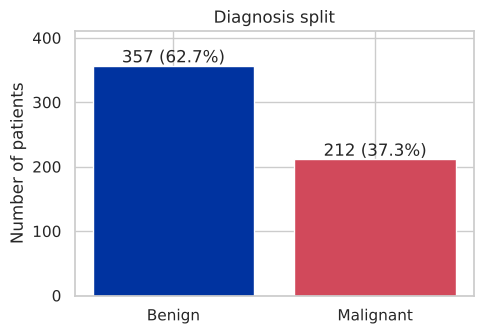

In [9]:
counts = df["diagnosis"].map({0: "Benign", 1: "Malignant"}).value_counts()
share = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"count": counts, "percent": share}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
for i, (c, p) in enumerate(zip(counts.values, share.values)):
    ax.text(i, c + 5, f"{c} ({p}%)", ha="center")
ax.set_ylabel("Number of patients")
ax.set_title("Diagnosis split")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig("figures/fig1_class_balance.png", dpi=150)
plt.show()

Roughly 63/37 benign to malignant. That's a moderate imbalance, not a severe one, but it does
mean accuracy alone would flatter the model: guessing "benign" for everyone already scores
about 63%. It also tells me to stratify the train/test split so both sets keep this ratio.

### 3.5 How each feature differs by diagnosis

Histograms split by class are the clearest way to see whether a feature separates the two
groups: the less the colours overlap, the more useful the feature.

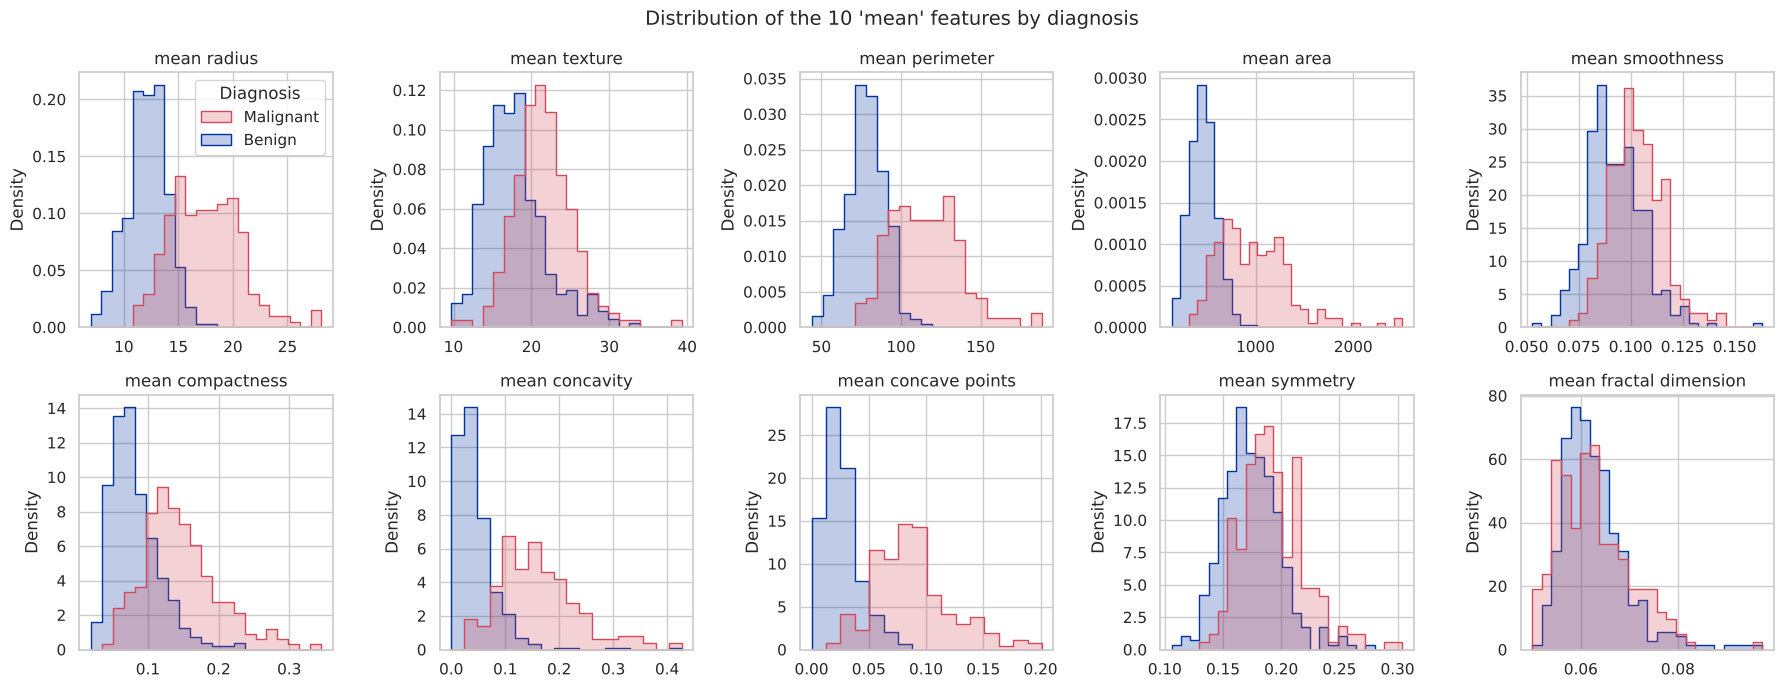

In [10]:
mean_cols = [c for c in features if c.startswith("mean ")]
plot_df = df.assign(Diagnosis=df["diagnosis"].map({0: "Benign", 1: "Malignant"}))

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.histplot(data=plot_df, x=col, hue="Diagnosis", palette=PALETTE,
                 element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    if ax is not axes.ravel()[0]:
        ax.get_legend().remove()
fig.suptitle("Distribution of the 10 'mean' features by diagnosis", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig2_distributions_by_class.png", dpi=150)
plt.show()

Size and shape features (radius, perimeter, area, concavity, concave points) separate the
classes clearly: malignant masses are bigger and more irregular. Smoothness, symmetry and
fractal dimension overlap heavily, so on their own they say little. Several features are also
right-skewed (long tail to the right), which I check next.

### 3.6 Outliers and skewness

In [11]:
# IQR rule: anything beyond 1.5 x IQR from the quartiles counts as an outlier
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).sum()

summary = pd.DataFrame({"outliers": outliers,
                        "skewness": df[features].skew().round(2)}).sort_values("outliers", ascending=False)
print("Rows with at least one IQR outlier:",
      ((df[features] < q1 - 1.5 * iqr) | (df[features] > q3 + 1.5 * iqr)).any(axis=1).sum())
summary.head(10)

Rows with at least one IQR outlier: 171


,outliers,skewness
area error,65,5.45
radius error,38,3.09
perimeter error,38,3.44
worst area,35,1.86
smoothness error,30,2.31
fractal dimension error,28,3.92
compactness error,28,1.90
symmetry error,27,2.20
mean area,25,1.65
worst fractal dimension,24,1.66


In [12]:
# Are the outliers mostly malignant? Check on 'area error', one of the worst offenders
col = "area error"
is_out = df[col] > q3[col] + 1.5 * iqr[col]
print(f"High outliers in '{col}':", is_out.sum())
print(df.loc[is_out, "diagnosis"].value_counts().rename({0: "Benign", 1: "Malignant"}))

High outliers in 'area error': 65
diagnosis
Malignant    65
Name: count, dtype: int64


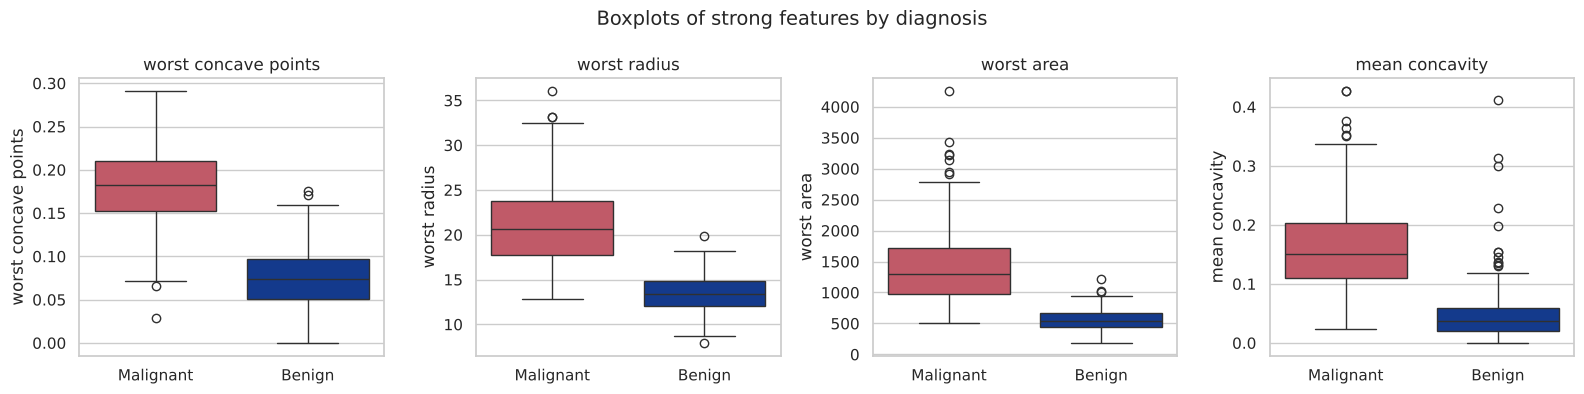

In [13]:
top_feats = ["worst concave points", "worst radius", "worst area", "mean concavity"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top_feats):
    sns.boxplot(data=plot_df, x="Diagnosis", y=col, hue="Diagnosis", palette=PALETTE,
                legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Boxplots of strong features by diagnosis", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig3_boxplots.png", dpi=150)
plt.show()

**Decision: keep the outliers.** They're not data-entry errors. All 65 high outliers in
`area error` are malignant, and the pattern is the same for the other size features: the extreme
values are malignant masses that really are larger and more irregular, so deleting them would remove
exactly the cases the model most needs to learn from. Standardizing the features and using
regularization limits how much any single extreme point can pull the model.

### 3.7 Correlation between features

A heatmap is the right chart here because it shows every feature pair at once.

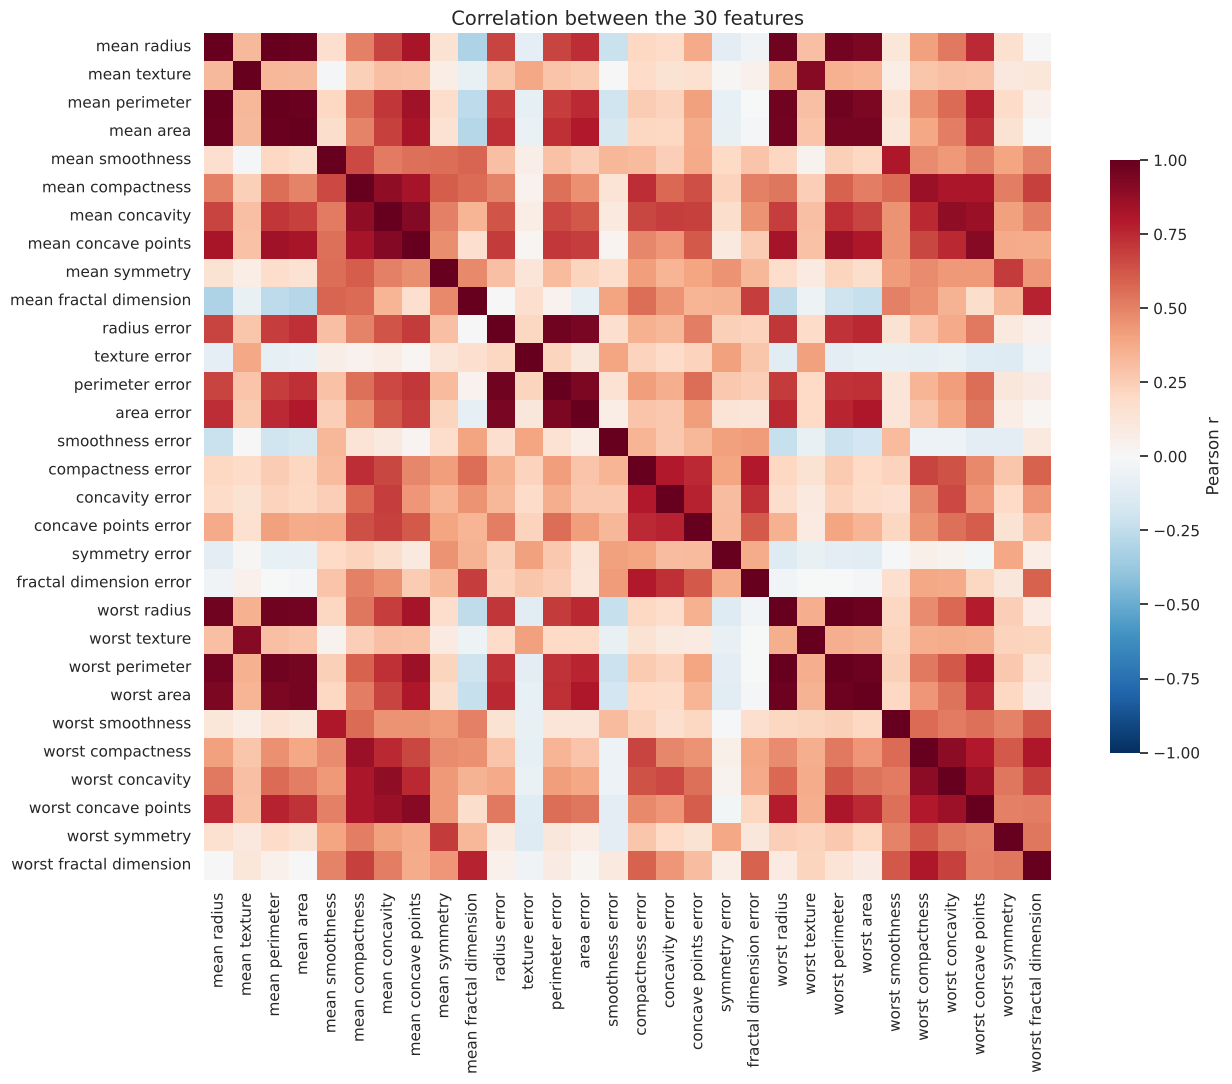

Feature pairs in total: 435
Feature pairs with |r| > 0.8: 44
Feature pairs with |r| > 0.95: 15


In [14]:
corr = df[features].corr()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation between the 30 features", fontsize=14)
plt.tight_layout()
plt.savefig("figures/fig4_correlation_heatmap.png", dpi=150)
plt.show()

# Count how many pairs are very highly correlated
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print("Feature pairs in total:", int(upper.notna().sum().sum()))
print("Feature pairs with |r| > 0.8:", (upper.abs() > 0.8).sum().sum())
print("Feature pairs with |r| > 0.95:", (upper.abs() > 0.95).sum().sum())

There's heavy multicollinearity (features that carry the same information). Radius, perimeter
and area are almost the same measurement because area and perimeter are calculated from the
radius, and the `mean` and `worst` versions of a property track each other closely. For
logistic regression this is a real problem: correlated inputs make coefficients unstable and
p-values unreliable. That drives the feature selection approach in section 5.

### 3.8 Correlation with the diagnosis

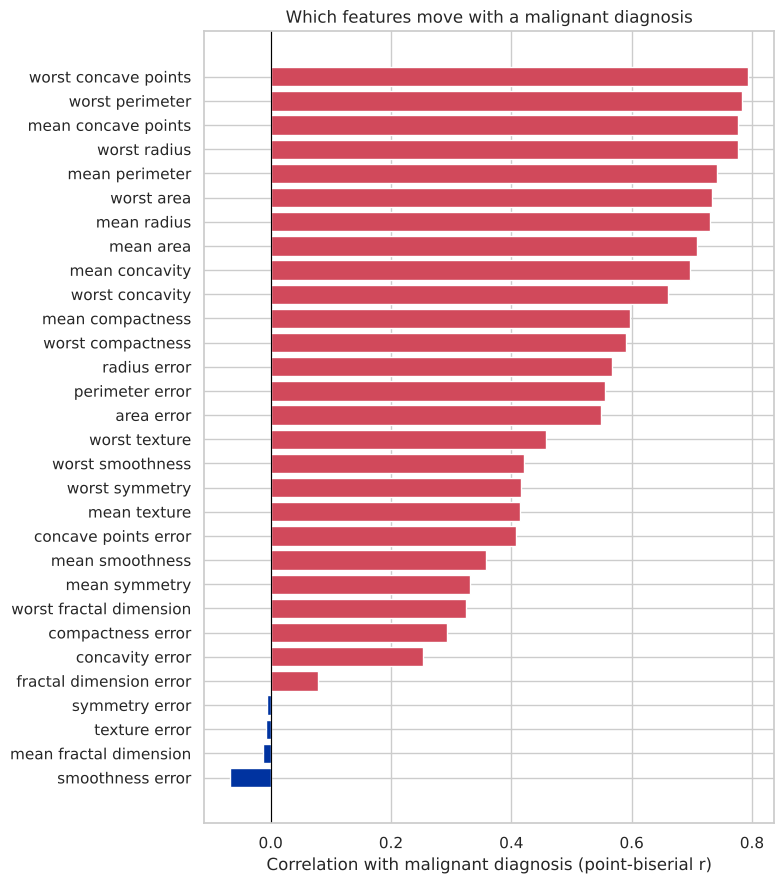

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
dtype: float64


In [15]:
target_corr = df[features].corrwith(df["diagnosis"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
colors = ["#D1495B" if v > 0 else "#0033A0" for v in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with malignant diagnosis (point-biserial r)")
ax.set_title("Which features move with a malignant diagnosis")
plt.tight_layout()
plt.savefig("figures/fig5_target_correlation.png", dpi=150)
plt.show()
print(target_corr.sort_values(ascending=False).head(8).round(3))

### EDA summary: what each finding means for the model

| EDA finding | Decision it drives | Where |
|---|---|---|
| No header, ID column, text labels | Name columns, drop ID, encode M = 1 | Section 2 |
| No missing values, duplicates or impossible values | No imputation or row removal needed | Section 3.2 |
| 13 zeros, all in concavity columns, all benign | Real values, keep them | Section 3.2 |
| 63/37 class split | Stratified split, recall-focused metrics, try `class_weight="balanced"` | Sections 4, 7, 8 |
| Features on very different scales | StandardScaler inside the pipeline | Section 6 |
| Outliers are mostly severe malignant cases | Keep them; rely on scaling and regularization | Section 3.6 |
| Heavy multicollinearity (44 pairs above 0.8) | Correlation filter and VIF before p-values | Section 5 |
| Size and concavity features separate best | Expect them to survive selection, check they do | Section 5.3 |

## 4. Prepare the data: train/test split

I split **before** feature selection. If I chose features using the whole dataset, the test
set would already have influenced the model (data leakage, where information from the test set
sneaks into training) and the test score would be optimistic (Muller and Guido, 2016).

In [16]:
X = df[features]
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| malignant share:", round(y_train.mean(), 3))
print("Test: ", X_test.shape, "| malignant share:", round(y_test.mean(), 3))
print("Malignant cases in test set:", int(y_test.sum()))

Train: (455, 30) | malignant share: 0.374
Test:  (114, 30) | malignant share: 0.368
Malignant cases in test set: 42


## 5. Feature selection

Three steps, all on the training set only:

1. **Correlation filter.** Rank features by how strongly they correlate with the diagnosis. Walk
   down the list and keep a feature only if it isn't correlated above 0.8 with one I've already
   kept. This keeps the stronger member of each near-duplicate group.
2. **VIF check.** The variance inflation factor (VIF) measures how much a feature can be
   predicted from the others. VIF = 1 / (1 - R squared). Above 10 is the usual warning sign.
3. **Backward elimination on p-values.** Fit a logistic regression with statsmodels, drop the
   feature with the highest p-value if it's above 0.05, refit, and repeat until every
   remaining feature is significant.

Step 3 only works properly after steps 1 and 2: with 30 overlapping features, the p-values are
inflated by multicollinearity and the model can fail to converge.

### 5.1 Correlation filter

In [17]:
corr_train = X_train.corr().abs()
target_rank = X_train.corrwith(y_train).abs().sort_values(ascending=False)

kept = []
for feat in target_rank.index:
    # keep this feature only if it isn't a near-duplicate of one already kept
    if all(corr_train.loc[feat, k] < 0.8 for k in kept):
        kept.append(feat)

print(f"Kept {len(kept)} of {len(features)} features:")
for f in kept:
    print(f"  {f:<26} r with diagnosis = {target_rank[f]:.3f}")

Kept 14 of 30 features:
  worst concave points       r with diagnosis = 0.786
  worst radius               r with diagnosis = 0.778
  radius error               r with diagnosis = 0.559
  worst texture              r with diagnosis = 0.467
  worst smoothness           r with diagnosis = 0.432
  worst symmetry             r with diagnosis = 0.426
  concave points error       r with diagnosis = 0.402
  mean symmetry              r with diagnosis = 0.341
  worst fractal dimension    r with diagnosis = 0.326
  compactness error          r with diagnosis = 0.285
  smoothness error           r with diagnosis = 0.057
  texture error              r with diagnosis = 0.007
  symmetry error             r with diagnosis = 0.006
  mean fractal dimension     r with diagnosis = 0.006


### 5.2 VIF check

In [18]:
def vif_table(frame):
    """Return the VIF for each column of a standardized copy of frame."""
    z = (frame - frame.mean()) / frame.std()
    z = sm.add_constant(z)
    vifs = [variance_inflation_factor(z.values, i) for i in range(1, z.shape[1])]
    return pd.Series(vifs, index=frame.columns, name="VIF").round(2).sort_values(ascending=False)

print("VIF on all 30 features (top 5):")
print(vif_table(X_train).head(5))
print("\nVIF after the correlation filter:")
print(vif_table(X_train[kept]))

VIF on all 30 features (top 5):
mean perimeter     4110.57
mean radius        4041.75
worst radius        799.62
worst perimeter     419.64
mean area           348.19
Name: VIF, dtype: float64

VIF after the correlation filter:
worst concave points       14.17
worst radius               10.29
worst fractal dimension     7.64
worst symmetry              7.13
mean fractal dimension      6.72
concave points error        5.34
worst smoothness            5.00
compactness error           4.79
symmetry error              4.33
radius error                4.24
mean symmetry               3.43
smoothness error            3.01
texture error               2.80
worst texture               2.48
Name: VIF, dtype: float64


On all 30 features the VIFs run into the thousands, which confirms the multicollinearity seen in
the heatmap. After the filter only `worst concave points` (14.2) and `worst radius` (10.3) are
still above 10. I don't drop them yet: they're the two strongest predictors, and backward
elimination removes features they overlap with. Section 5.3 rechecks the VIF on what survives.

### 5.3 Backward elimination on p-values

In [19]:
def backward_elimination(X_frame, y_series, alpha=0.05):
    """Drop the least significant feature one at a time until all p-values < alpha."""
    feats = list(X_frame.columns)
    while True:
        z = (X_frame[feats] - X_frame[feats].mean()) / X_frame[feats].std()
        model = sm.Logit(y_series, sm.add_constant(z)).fit(disp=0)
        pvals = model.pvalues.drop("const")
        worst = pvals.idxmax()
        if pvals[worst] > alpha:
            print(f"Dropping {worst:<26} p = {pvals[worst]:.4f}")
            feats.remove(worst)
        else:
            return feats, model

selected, logit_model = backward_elimination(X_train[kept], y_train)
print(f"\nFinal {len(selected)} features:", selected)

Dropping smoothness error           p = 0.8439
Dropping mean fractal dimension     p = 0.6696
Dropping worst fractal dimension    p = 0.6601


Dropping symmetry error             p = 0.7507


Dropping mean symmetry              p = 0.2900
Dropping worst symmetry             p = 0.0695
Dropping concave points error       p = 0.1533


Dropping worst smoothness           p = 0.0809

Final 6 features: ['worst concave points', 'worst radius', 'radius error', 'worst texture', 'compactness error', 'texture error']


In [20]:
logit_model.summary2().tables[1].round(4)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-0.4062,0.4445,-0.9137,0.3609,-1.2775,0.4651
worst concave points,5.0235,1.1442,4.3904,0.0000,2.7809,7.2661
worst radius,3.8526,1.2457,3.0927,0.0020,1.4111,6.2942
radius error,5.8354,1.7864,3.2665,0.0011,2.3340,9.3367
worst texture,3.6145,0.8818,4.0989,0.0000,1.8861,5.3428
compactness error,-1.0948,0.5055,-2.1660,0.0303,-2.0855,-0.1042
texture error,-1.5817,0.7919,-1.9974,0.0458,-3.1337,-0.0296


In [21]:
print("VIF of the final features:")
print(vif_table(X_train[selected]))
print("\nPseudo R-squared (McFadden):", round(logit_model.prsquared, 3))

VIF of the final features:
worst radius            5.65
worst concave points    4.35
radius error            3.11
texture error           1.98
compactness error       1.89
worst texture           1.82
Name: VIF, dtype: float64

Pseudo R-squared (McFadden): 0.907


Six features survive, all significant at the 5% level and all with VIF below 10. They make
sense clinically too: `worst concave points` and `worst radius` capture how irregular and how
large the most abnormal nuclei are, `worst texture` captures variation in grey level, and the
three `error` features capture how variable the nuclei are within one sample.

`texture error` and `compactness error` come out with negative coefficients here even though
on their own they're barely related to the diagnosis. That's a conditional effect (it holds
only once the other features are in the model), so I don't read too much into their sign.
`texture error` is also only just under 0.05, so it's the least secure of the six.

**Alternatives I considered:** forward selection (add the most significant feature one at a
time) usually lands in a similar place; recursive feature elimination (RFE) or L1
regularization select features by predictive power rather than significance. P-value backward
elimination fits this brief because the scheme needs to be able to explain *why* the model
flags a claim.

## 6. Train the baseline model

The scaler and the model go into one pipeline, so the scaler learns its means and standard
deviations from the training data only (in cross-validation too, from each training fold only).

Hyperparameters for the baseline (scikit-learn defaults, apart from `max_iter`):

| Hyperparameter | Value | What it does |
|---|---|---|
| `C` | 1.0 | Inverse of regularization strength. Smaller C = simpler model |
| `penalty` | L2 (default) | Shrinks coefficients towards zero to reduce overfitting |
| `solver` | lbfgs | Optimization algorithm; fine for a small dataset |
| `class_weight` | None | Every patient counts equally |
| `max_iter` | 1000 | Raised from 100 so the solver always converges |
| threshold | 0.5 | Probability above which a case is called malignant |

In [22]:
baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE))

baseline.fit(X_train[selected], y_train)
print("Coefficients (standardized features):")
print(pd.Series(baseline[-1].coef_[0], index=selected).round(3))

Coefficients (standardized features):
worst concave points    2.608
worst radius            2.405
radius error            2.283
worst texture           1.795
compactness error      -0.371
texture error          -0.643
dtype: float64


## 7. Evaluate the baseline

### Which metrics, and why

The scheme's job here is to get benefits to people who have cancer, quickly. The two possible
mistakes cost very different amounts:

- **False negative** (malignant called benign): a member with cancer is not fast-tracked. Their
  claim is delayed, which is the exact problem the scheme wants to fix, and it damages trust.
- **False positive** (benign called malignant): a claim gets sent to a clinical reviewer who
  then declines it. That costs some reviewer time, not much else.

So the metrics, in order of importance:

| Metric | Formula | Why it's here |
|---|---|---|
| Recall (sensitivity) | TP / (TP + FN) | Share of real cancers caught. **Primary metric** |
| Precision | TP / (TP + FP) | Share of flagged cases that really are cancer; controls reviewer workload |
| Specificity | TN / (TN + FP) | Share of benign cases correctly cleared |
| F1 and F2 | weighted harmonic mean of precision and recall; F2 weights recall twice as much | One-number summaries; F2 matches this brief |
| ROC-AUC | area under the ROC curve | How well the model ranks malignant above benign, at any threshold |
| PR-AUC (average precision) | area under the precision-recall curve | Like ROC-AUC but focused on the malignant class, so less flattering under imbalance (Saito and Rehmsmeier, 2015) |
| Accuracy | (TP + TN) / total | Reported, but not trusted alone given the 63/37 split |

I report 5-fold cross-validation on the training set (a more stable estimate) and a single
score on the held-out test set (the final, unseen check).

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
f2_scorer = make_scorer(fbeta_score, beta=2)
scoring = {"accuracy": "accuracy", "recall": "recall", "precision": "precision",
           "f1": "f1", "f2": f2_scorer, "roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_base = cross_validate(baseline, X_train[selected], y_train, cv=cv, scoring=scoring)
cv_summary = pd.DataFrame({m: [cv_base[f"test_{m}"].mean(), cv_base[f"test_{m}"].std()]
                           for m in scoring}, index=["mean", "std"]).round(4)
print("Baseline, 5-fold CV on the training set")
cv_summary

Baseline, 5-fold CV on the training set


,accuracy,recall,precision,f1,f2,roc_auc,pr_auc
mean,0.9604,0.9235,0.9696,0.9454,0.9320,0.9963,0.9951
std,0.0149,0.0399,0.0182,0.0218,0.0323,0.0033,0.0031


In [24]:
def evaluate(model, X_eval, y_eval, threshold=0.5, name="model"):
    """Score a fitted model at a given threshold and return the metrics as a dict."""
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    return {"model": name, "threshold": threshold,
            "accuracy": accuracy_score(y_eval, pred),
            "recall": recall_score(y_eval, pred),
            "precision": precision_score(y_eval, pred),
            "specificity": tn / (tn + fp),
            "f1": f1_score(y_eval, pred),
            "f2": fbeta_score(y_eval, pred, beta=2),
            "roc_auc": roc_auc_score(y_eval, proba),
            "pr_auc": average_precision_score(y_eval, proba),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}

base_res = evaluate(baseline, X_test[selected], y_test, name="Baseline (6 features)")
pd.Series(base_res)

model          Baseline (6 features)
threshold                        0.5
accuracy                    0.964912
recall                      0.928571
precision                      0.975
specificity                 0.986111
f1                           0.95122
f2                            0.9375
roc_auc                     0.996362
pr_auc                      0.993539
TP                                39
FN                                 3
FP                                 1
TN                                71
dtype: object

In [25]:
print(classification_report(y_test, baseline.predict(X_test[selected]),
                            target_names=["Benign", "Malignant"], digits=3))

              precision    recall  f1-score   support

      Benign      0.959     0.986     0.973        72
   Malignant      0.975     0.929     0.951        42

    accuracy                          0.965       114
   macro avg      0.967     0.957     0.962       114
weighted avg      0.965     0.965     0.965       114



### Sanity checks

A model is only good relative to something. I compare against a majority-class "model" that
always says benign, and against logistic regression on all 30 features, to check that dropping
24 features didn't cost performance.

In [26]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
full30 = make_pipeline(StandardScaler(),
                       LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)).fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)
checks = pd.DataFrame([
    {"model": "Always 'benign'", "accuracy": accuracy_score(y_test, dummy_pred),
     "recall": recall_score(y_test, dummy_pred)},
    {k: evaluate(full30, X_test, y_test, name="All 30 features")[k] for k in ["model", "accuracy", "recall"]},
    {k: base_res[k] for k in ["model", "accuracy", "recall"]},
]).round(4)
checks

,model,accuracy,recall
0,Always 'benign',0.6316,0.0000
1,All 30 features,0.9649,0.9286
2,Baseline (6 features),0.9649,0.9286


The always-benign model gets about 63% accuracy but catches zero cancers, which is why accuracy
can't be the headline metric. The 6-feature model matches the 30-feature model on the test set,
so feature selection made the model simpler and easier to explain without losing anything.

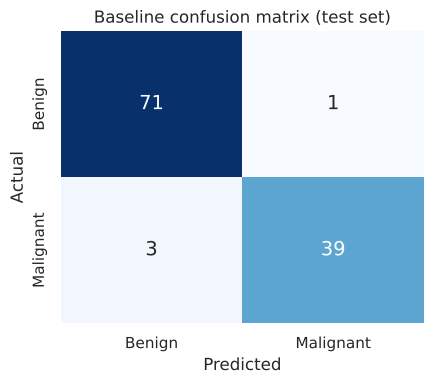

In [27]:
def plot_cm(ax, res, title):
    cm = np.array([[res["TN"], res["FP"]], [res["FN"], res["TP"]]]).astype(int)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"],
                annot_kws={"size": 14})
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(4.5, 4))
plot_cm(ax, base_res, "Baseline confusion matrix (test set)")
plt.tight_layout()
plt.savefig("figures/fig6_cm_baseline.png", dpi=150)
plt.show()

### Baseline verdict

Strong overall (ROC-AUC near 1 means the model ranks almost every malignant case above every
benign one), but at the default 0.5 threshold it still misses **3 of 42 malignant cases** in
the test set. For this brief that's the shortcoming to fix: those are three members with
cancer whose claims would not be fast-tracked.

## 8. Retrain to address the shortcoming

Two changes, both chosen with cross-validation on the **training set only**, so the test set
stays untouched until the final check:

1. **Hyperparameter search.** Grid search over `C` (regularization strength) and
   `class_weight` (`balanced` makes each malignant case count more, roughly in proportion to
   the 63/37 split). Scored on F2, because F2 rewards recall twice as much as precision.
2. **Decision threshold.** Because the ranking (ROC-AUC) is already excellent, the biggest lever
   is where I draw the line. I get out-of-fold probabilities (each training row is predicted by
   a model that didn't see it) and pick the threshold with the best F2.

In [28]:
param_grid = {"logisticregression__C": [0.01, 0.1, 1, 10, 100],
              "logisticregression__class_weight": [None, "balanced"]}

search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    param_grid, scoring=f2_scorer, cv=cv)
search.fit(X_train[selected], y_train)

print("Best parameters:", search.best_params_)
print("Best CV F2:", round(search.best_score_, 4))

grid_results = (pd.DataFrame(search.cv_results_)
                [["param_logisticregression__C", "param_logisticregression__class_weight",
                  "mean_test_score", "std_test_score"]]
                .rename(columns={"param_logisticregression__C": "C",
                                 "param_logisticregression__class_weight": "class_weight",
                                 "mean_test_score": "mean CV F2", "std_test_score": "std"})
                .sort_values("mean CV F2", ascending=False).round(4))
grid_results["class_weight"] = grid_results["class_weight"].map(lambda v: v if v == "balanced" else "None")
grid_results

Best parameters: {'logisticregression__C': 10, 'logisticregression__class_weight': 'balanced'}
Best CV F2: 0.9683


,C,class_weight,mean CV F2,std
7,10.00,balanced,0.9683,0.0176
9,100.00,balanced,0.9660,0.0167
5,1.00,balanced,0.9647,0.0105
8,100.00,None,0.9493,0.0061
3,0.10,balanced,0.9452,0.0386
6,10.00,None,0.9419,0.0168
4,1.00,None,0.9320,0.0323
1,0.01,balanced,0.9268,0.0422
2,0.10,None,0.9157,0.0370
0,0.01,None,0.8478,0.0568


In [29]:
tuned = search.best_estimator_

# Out-of-fold probabilities: honest predictions for every training row
oof_proba = cross_val_predict(tuned, X_train[selected], y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.20, 0.61, 0.05), 2)
thr_table = pd.DataFrame([{
    "threshold": t,
    "recall": recall_score(y_train, oof_proba >= t),
    "precision": precision_score(y_train, oof_proba >= t),
    "f2": fbeta_score(y_train, oof_proba >= t, beta=2)} for t in thresholds]).round(4)

best_threshold = float(thr_table.loc[thr_table["f2"].idxmax(), "threshold"])
print("Threshold with the best out-of-fold F2:", best_threshold)
thr_table

Threshold with the best out-of-fold F2: 0.4


,threshold,recall,precision,f2
0,0.20,0.9824,0.8883,0.9620
1,0.25,0.9824,0.9076,0.9664
2,0.30,0.9824,0.9176,0.9687
3,0.35,0.9765,0.9274,0.9662
4,0.40,0.9765,0.9486,0.9708
5,0.45,0.9706,0.9538,0.9672
6,0.50,0.9706,0.9593,0.9683
7,0.55,0.9647,0.9647,0.9647
8,0.60,0.9471,0.9699,0.9515


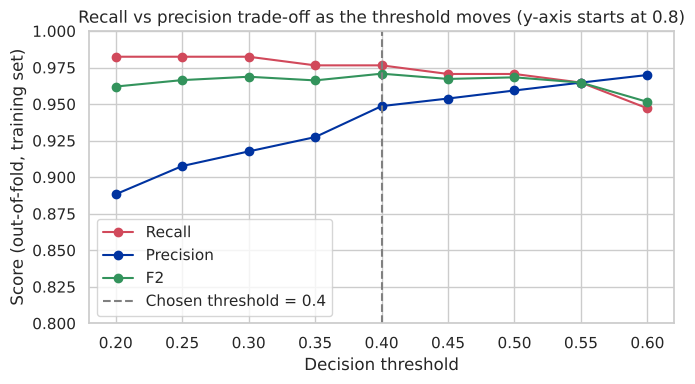

In [30]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr_table["threshold"], thr_table["recall"], marker="o", label="Recall", color="#D1495B")
ax.plot(thr_table["threshold"], thr_table["precision"], marker="o", label="Precision", color="#0033A0")
ax.plot(thr_table["threshold"], thr_table["f2"], marker="o", label="F2", color="#33935C")
ax.axvline(best_threshold, linestyle="--", color="grey", label=f"Chosen threshold = {best_threshold}")
ax.set_ylim(0.8, 1.0)   # axis zoomed to show the trade-off; all three metrics sit above 0.8
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score (out-of-fold, training set)")
ax.set_title("Recall vs precision trade-off as the threshold moves (y-axis starts at 0.8)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig7_threshold_tradeoff.png", dpi=150)
plt.show()

Lowering the threshold catches more malignant cases at the price of more false alarms. The
chosen threshold is the point where F2 peaks. Note the y-axis starts at 0.8 to make the small
differences visible; that's labelled on the chart so it doesn't exaggerate the gaps.

### Final check on the untouched test set

In [31]:
results = pd.DataFrame([
    base_res,
    evaluate(tuned, X_test[selected], y_test, threshold=0.5, name="Tuned, threshold 0.5"),
    evaluate(tuned, X_test[selected], y_test, threshold=best_threshold,
             name=f"Tuned, threshold {best_threshold} (final)"),
]).set_index("model")
print("One malignant patient is worth", round(100 / y_test.sum(), 1), "percentage points of test recall")
results.round(4)

One malignant patient is worth 2.4 percentage points of test recall


,threshold,accuracy,recall,precision,specificity,f1,f2,roc_auc,pr_auc,TP,FN,FP,TN
model,,,,,,,,,,,,,
Baseline (6 features),0.5,0.9649,0.9286,0.9750,0.9861,0.9512,0.9375,0.9964,0.9935,39,3,1,71
"Tuned, threshold 0.5",0.5,0.9474,0.9048,0.9500,0.9722,0.9268,0.9135,0.9957,0.9924,38,4,2,70
"Tuned, threshold 0.4 (final)",0.4,0.9649,0.9524,0.9524,0.9722,0.9524,0.9524,0.9957,0.9924,40,2,2,70


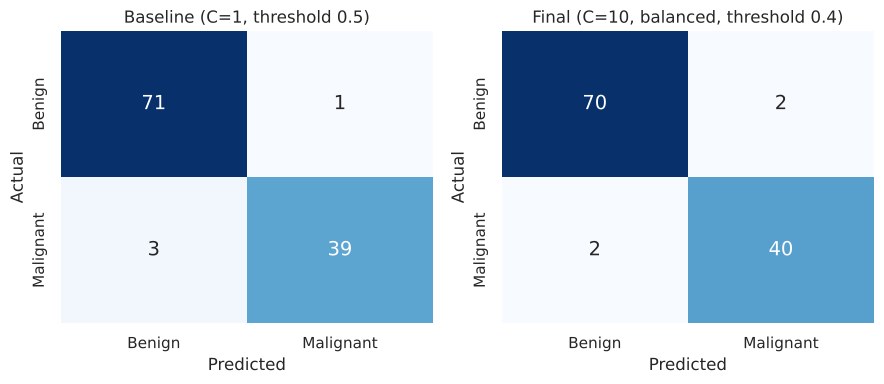

In [32]:
final_res = results.iloc[-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_cm(axes[0], base_res, "Baseline (C=1, threshold 0.5)")
plot_cm(axes[1], final_res, f"Final (C={search.best_params_['logisticregression__C']}, "
                            f"balanced, threshold {best_threshold})")
plt.tight_layout()
plt.savefig("figures/fig8_cm_comparison.png", dpi=150)
plt.show()

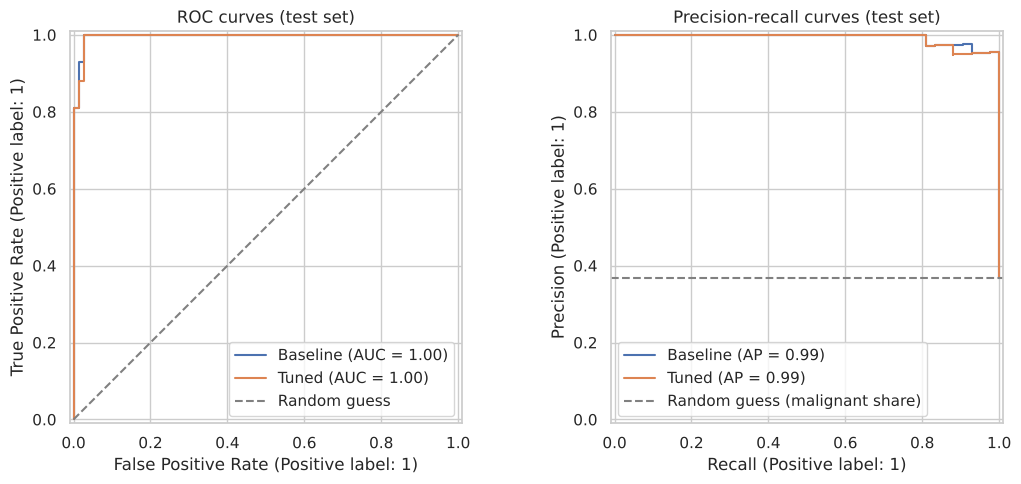

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
RocCurveDisplay.from_estimator(baseline, X_test[selected], y_test, name="Baseline", ax=ax1)
RocCurveDisplay.from_estimator(tuned, X_test[selected], y_test, name="Tuned", ax=ax1)
ax1.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
ax1.set_title("ROC curves (test set)")
ax1.legend(loc="lower right")

PrecisionRecallDisplay.from_estimator(baseline, X_test[selected], y_test, name="Baseline", ax=ax2)
PrecisionRecallDisplay.from_estimator(tuned, X_test[selected], y_test, name="Tuned", ax=ax2)
ax2.axhline(y_test.mean(), linestyle="--", color="grey", label="Random guess (malignant share)")
ax2.set_title("Precision-recall curves (test set)")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.savefig("figures/fig9_roc.png", dpi=150)
plt.show()

### What changed and what it bought

The retrained model catches more of the malignant cases in the test set, for a small rise in
false alarms. Two honest caveats:

- At the default 0.5 threshold the tuned model actually did slightly *worse* on the test set
  than the baseline, even though it was better in cross-validation. With only 42 malignant test
  cases, one patient moves recall by about 2.4 percentage points, so single-split differences
  this small are noise. That's why I made every choice on cross-validation, not on the test set.
- ROC-AUC barely moves. The ranking was already near perfect; the improvement comes from
  where the line is drawn, which is a business decision about how many false alarms the
  reviewers can absorb.

### 8.1 Benchmark: was logistic regression the right choice?

To back up the algorithm choice with evidence rather than just argument, I ran five other
common classifiers through the same 5-fold cross-validation on the same six features and the
same training set. Distance and margin based models (KNN, SVM) get the same scaler. The test
set stays untouched.

In [34]:
candidates = {
    "Logistic regression (final settings)": tuned,
    "K-nearest neighbours (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "Support vector machine (RBF)": make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest (200 trees)": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gaussian naive Bayes": GaussianNB(),
}

bench_rows = []
for name, model in candidates.items():
    scores = cross_validate(model, X_train[selected], y_train, cv=cv,
                            scoring={"recall": "recall", "precision": "precision",
                                     "f2": f2_scorer, "roc_auc": "roc_auc"})
    bench_rows.append({"model": name, **{m: scores[f"test_{m}"].mean() for m in ["recall", "precision", "f2", "roc_auc"]}})

benchmark = pd.DataFrame(bench_rows).set_index("model").sort_values("f2", ascending=False).round(4)
benchmark

,recall,precision,f2,roc_auc
model,,,,
Logistic regression (final settings),0.9706,0.9600,0.9683,0.9960
Random forest (200 trees),0.9412,0.9592,0.9444,0.9924
Support vector machine (RBF),0.9353,0.9641,0.9407,0.9959
K-nearest neighbours (k=5),0.9059,0.9751,0.9186,0.9850
Gaussian naive Bayes,0.9059,0.9630,0.9163,0.9906
Decision tree,0.9059,0.9148,0.9060,0.9266


Logistic regression comes out on top for recall (0.9706), F2 (0.9683) and ROC-AUC (0.9960).
The decision tree is the weakest, which is typical: a single tree overfits small datasets.
Random forest and SVM come close but don't beat it, and they would cost the explainability the
scheme needs.

One fairness caveat: logistic regression here uses the tuned settings, while the others run on
defaults. So this doesn't prove logistic regression is the best possible model. What it does
show is that nothing off the shelf clearly beats it, so there's no accuracy reason to give up
its interpretability.

## 9. Interpret the final model

Because the features are standardized, each coefficient is the change in log-odds of malignancy
for a one standard deviation increase in that feature, holding the others fixed. Exponentiating
gives an **odds ratio**: above 1 raises the odds of malignancy, below 1 lowers them.

For example, an odds ratio of 61 for `worst concave points` means one standard deviation more
of it multiplies the odds of malignancy by about 61. The numbers are large because the classes
separate so cleanly and C = 10 applies only light regularization; the ranking of the features
matters more than the exact values.

                      coefficient  odds_ratio
texture error              -1.087       0.337
compactness error          -0.849       0.428
worst texture               2.911      18.368
worst radius                3.408      30.192
worst concave points        4.115      61.228
radius error                4.373      79.295


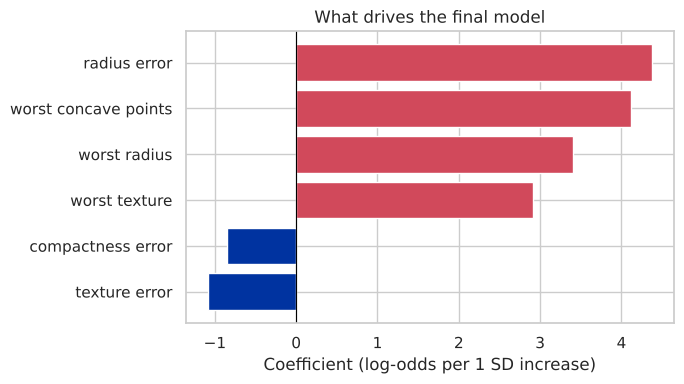

In [35]:
coefs = pd.Series(tuned[-1].coef_[0], index=selected)
odds = pd.DataFrame({"coefficient": coefs, "odds_ratio": np.exp(coefs)}).sort_values("coefficient")
print(odds.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(odds.index, odds["coefficient"],
        color=["#D1495B" if v > 0 else "#0033A0" for v in odds["coefficient"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds per 1 SD increase)")
ax.set_title("What drives the final model")
plt.tight_layout()
plt.savefig("figures/fig10_coefficients.png", dpi=150)
plt.show()

## 10. Validation of the code

### Worked test case

Two real patients from the test set (the first benign and the first malignant one), run
through the final model end to end, plus Patient C, the test patient whose probability sits
closest to the threshold (the hardest call). Expected: A clearly benign, B clearly malignant,
C close to the line.

In [36]:
# First benign patient, first malignant patient, and the patient closest to the threshold
first_benign = y_test[y_test == 0].index[0]
first_malig = y_test[y_test == 1].index[0]
test_proba = pd.Series(tuned.predict_proba(X_test[selected])[:, 1], index=X_test.index)
borderline = (test_proba - best_threshold).abs().idxmin()
cases = X_test.loc[[first_benign, first_malig, borderline], selected]
probs = tuned.predict_proba(cases)[:, 1]

worked = cases.T.round(4)
worked.columns = ["Patient A", "Patient B", "Patient C"]
worked.loc["P(malignant)"] = [f"{p:.4f}" for p in probs]
worked.loc["Predicted"] = ["Malignant" if p >= best_threshold else "Benign" for p in probs]
worked.loc["Actual"] = ["Malignant" if v == 1 else "Benign" for v in y_test.loc[cases.index]]
worked

,Patient A,Patient B,Patient C
worst concave points,0.0896,0.2105,0.1772
worst radius,12.82,25.58,15.74
radius error,0.1408,1.004,0.286
worst texture,15.97,27.0,37.18
compactness error,0.0153,0.0391,0.1354
texture error,0.4607,0.8208,2.11
P(malignant),0.0000,1.0000,0.4482
Predicted,Benign,Malignant,Malignant
Actual,Benign,Malignant,Malignant


All three behave as expected. Patient C is the interesting one: a malignant case with a
probability of about 0.45. At the default threshold of 0.5 the model would have called this
benign and the claim would not have been fast-tracked. At the chosen threshold of 0.4 it's
caught. That one patient is the retraining step paying off.

In [37]:
# Recompute the final metrics by hand from the confusion matrix and check they match sklearn
tp, fn, fp, tn = (int(final_res[k]) for k in ["TP", "FN", "FP", "TN"])
manual = {"recall": tp / (tp + fn), "precision": tp / (tp + fp),
          "specificity": tn / (tn + fp), "accuracy": (tp + tn) / (tp + tn + fp + fn)}
for metric, value in manual.items():
    assert abs(value - final_res[metric]) < 1e-12, metric
assert tp + fn == int(y_test.sum()), "TP + FN should equal the number of malignant test cases"
print("All hand-calculated metrics match:", {k: round(v, 4) for k, v in manual.items()})

All hand-calculated metrics match: {'recall': 0.9524, 'precision': 0.9524, 'specificity': 0.9722, 'accuracy': 0.9649}


## 11. Conclusion and limitations

- Logistic regression on six p-value-selected features separates malignant from benign masses
  very well (test ROC-AUC above 0.99).
- The baseline missed 3 of 42 malignant test cases. Retraining with class weighting, a tuned
  `C` and a recall-focused threshold, all chosen by cross-validation, cut that to 2, at the
  cost of one extra false alarm.

**Limitations**

- The data comes from one US hospital in the early 1990s and only covers breast masses. Before
  this goes anywhere near real claims it would need validating on the scheme's own data and on
  other cancers.
- The test set is small (114 patients, 42 malignant), so test scores carry real uncertainty.
  Repeated cross-validation or bootstrapped confidence intervals would firm them up.
- The model supports a human decision; it should fast-track claims to a clinician, never
  decline them automatically. Member medical data falls under POPIA (the Protection of
  Personal Information Act), so any real deployment needs consent and access controls.

## References

Muller, A.C. and Guido, S. (2016) *Introduction to machine learning with Python: a guide for data scientists*. Sebastopol, CA: O'Reilly Media.

Wolberg, W., Mangasarian, O., Street, N. and Street, W. (1993) *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5DW2B (Accessed: 21 October 2026).